# Imports

In [1]:
%load_ext autoreload
%autoreload 2

In [4]:
import explore_rothamsted_repositories as err

# What's Available?
The Rothamsted Rsearch Centerwas scanner using LIDAR and a UAV
This resulted in a very dense single dataset that can be found on FIGSHARE: https://figshare.com/s/33033e7c6b4cad12e301 -> Full Site Dense Point Cloud.zip
This file is associated to two textures files.

The full site was split into 5 smaller maps, each associated to a single texture file (probably higher resolution then). These smaller models can be found on the same figshare.

All these files are very dense and we can not render view using the antworld rendering program.


There exist a second repository, where the 5 small models were downsampled to a manageable size, its on the Brains on Board (BoB) github: https://github.com/BrainsOnBoard/rothamsted_reconstruction/tree/master/flights 

However, its seems hat for some reason (see below) these models are tilted and, do not properly overlap anymore.
1km².

### From FIGSHARE:
- **Denser Models**: 10x denser than Lig from BoBht Models.
- **Small Maps**: Same 1km² size, but denser.
- **VERY Large Model**: Spans the area of all 5 smaller models. Needs to be 

### From Brains On Board GitHub:
- **Tilted for some reason, There's a mismatch in height when trying to merge the small maps.**
- **Light Models**: Around 500,000 vertices each.
- **Small Maps**: 1km².

## The goal of this notebook is:
 - First visualize the maps in the figshare and BoB github.
 - Then proceed to downsample the large and dense model from the Figgshare.
 - Then stitch it to a large 100 square kilometers ring map to prevent the horizon from disappearing.d small maps.


# Understanding the Brains On Board maps
# Downloading the .obj files from the figshare or Brain on Board github is required to run this notebook
## Retrieve the vertices of all models (BoB)

In [5]:
vertices_1 = err.read_obj_vertices("ROTHAMSTED/FLIGHT1BOB/Flight_1.obj")
print(vertices_1.shape)

(445502, 3)


In [6]:
vertices_2 = err.read_obj_vertices("ROTHAMSTED/FLIGHT2BOB/Flight_2.obj")
print(vertices_2.shape)

(528233, 3)


In [7]:
vertices_3 = err.read_obj_vertices("ROTHAMSTED/FLIGHT3BOB/Flight_3.obj")
print(vertices_3.shape)

(437138, 3)


In [8]:
vertices_4 = err.read_obj_vertices("ROTHAMSTED/FLIGHT4BOB/Flight_4.obj")
print(vertices_4.shape)

(840791, 3)


In [9]:
vertices_5 = err.read_obj_vertices("ROTHAMSTED/FLIGHT5BOB/Flight_5.obj")
print(vertices_5.shape)

(384270, 3)


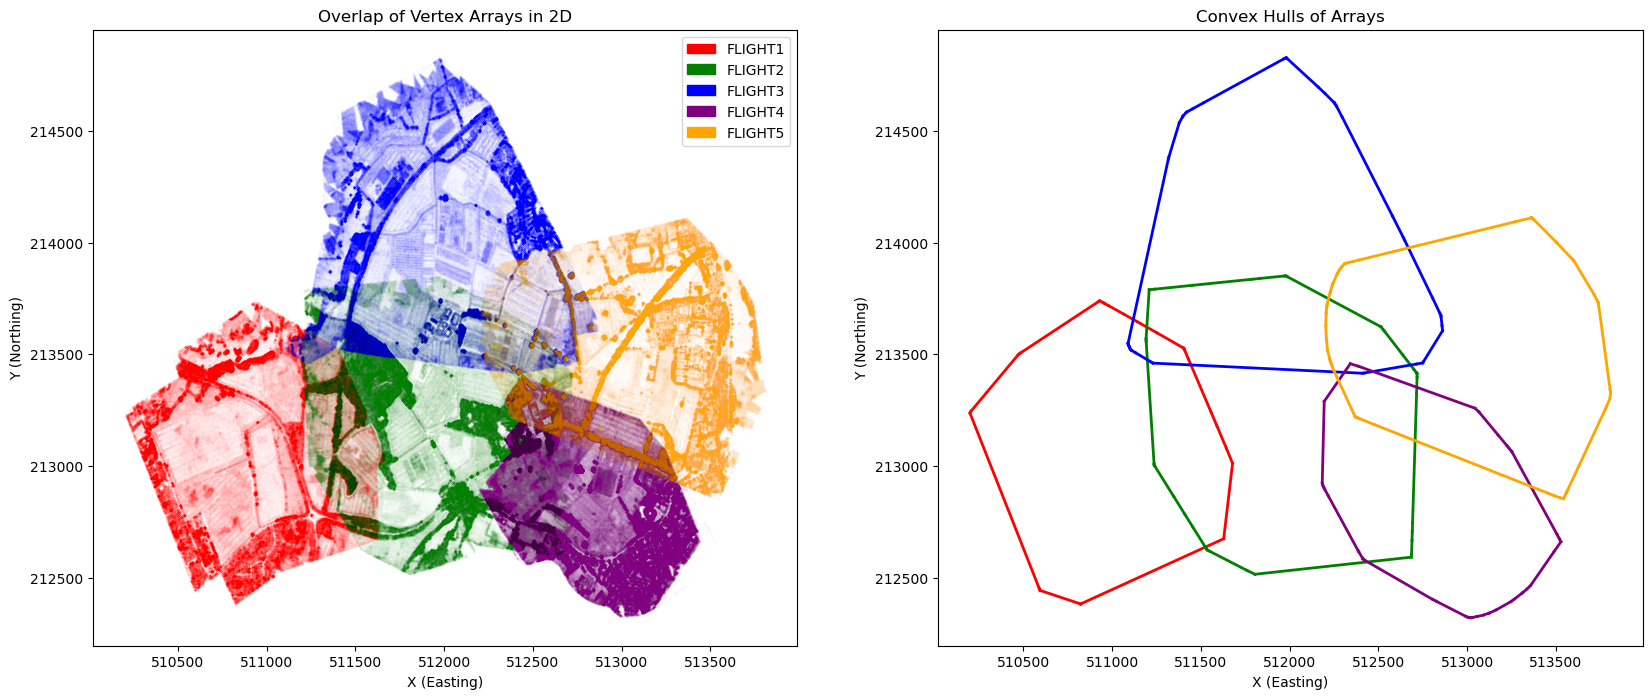

In [10]:
vertices_list = [vertices_1, vertices_2, vertices_3, vertices_4, vertices_5]
labels = labels=["FLIGHT1", "FLIGHT2", "FLIGHT3", "FLIGHT4", "FLIGHT5"]
colors = ['red', 'green', 'blue', 'purple', 'orange']
err.plot_vertex_overlaps_with_hulls(vertices_list, labels, colors)

# Height discrepancies between overlapping maps

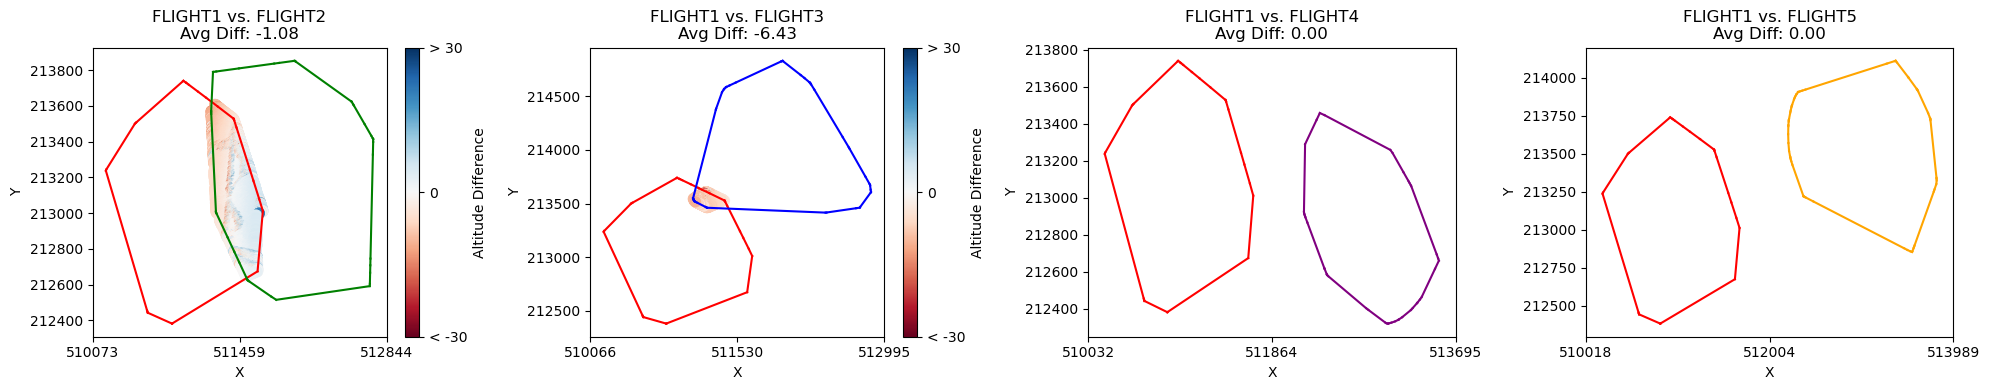

In [11]:
err.plot_patches_comparison(patches = vertices_list, ref_index=0, dist=1, colors=colors, labels=labels)

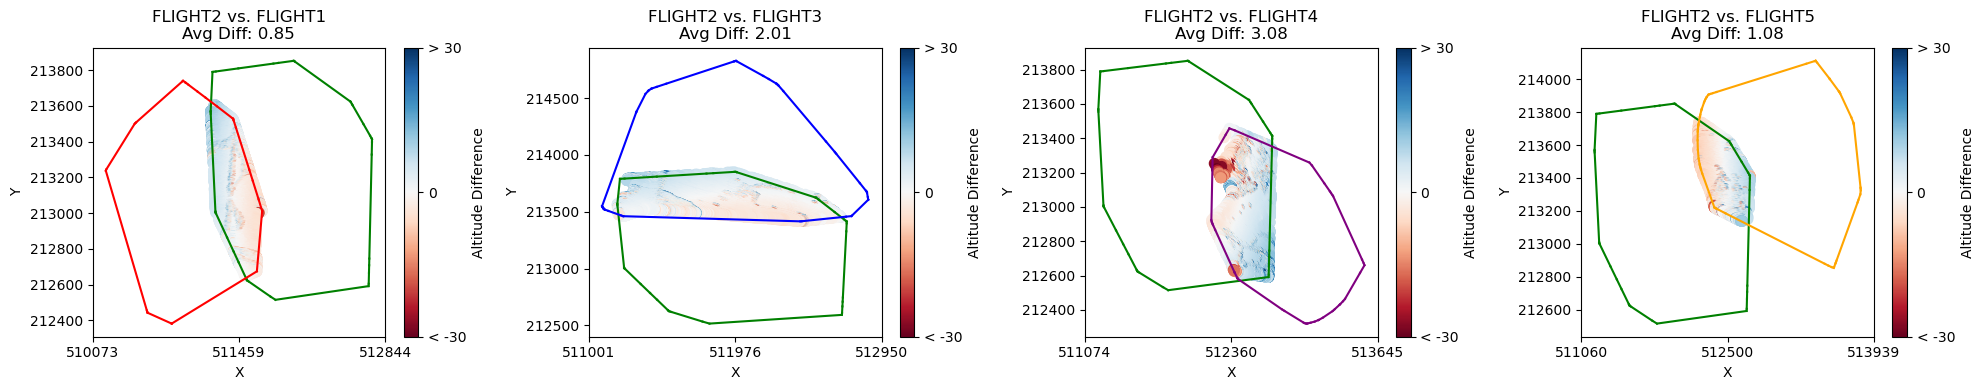

In [12]:
err.plot_patches_comparison(patches = vertices_list, ref_index=1, dist=1, colors=colors, labels=labels)

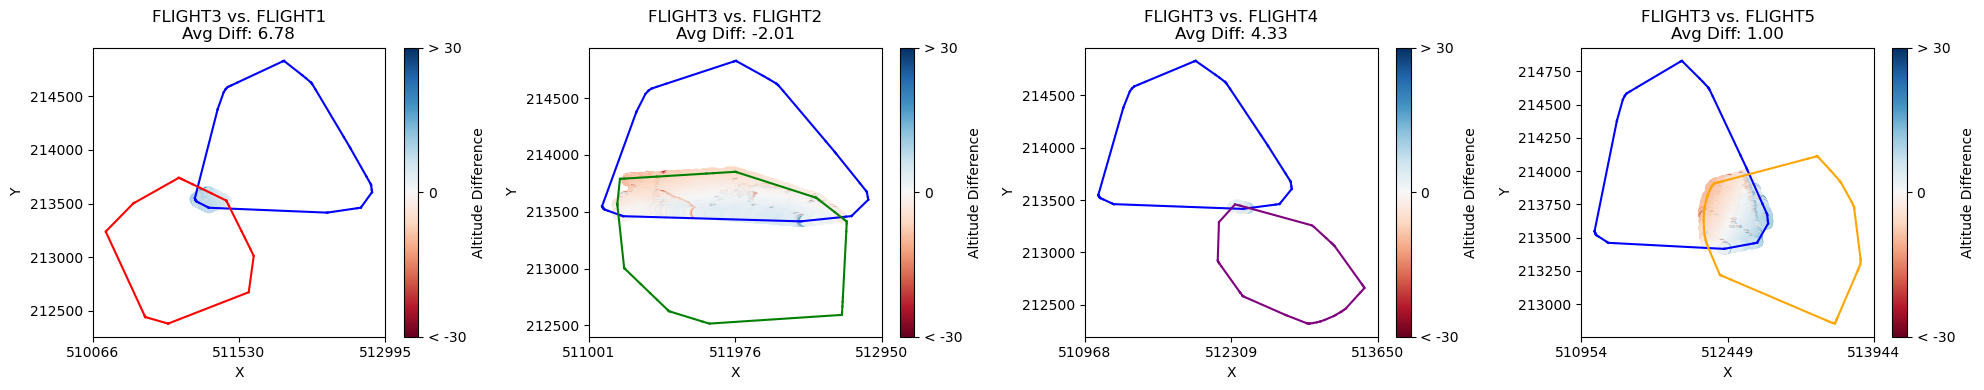

In [13]:
err.plot_patches_comparison(patches = vertices_list, ref_index=2, dist=1, colors=colors, labels=labels)

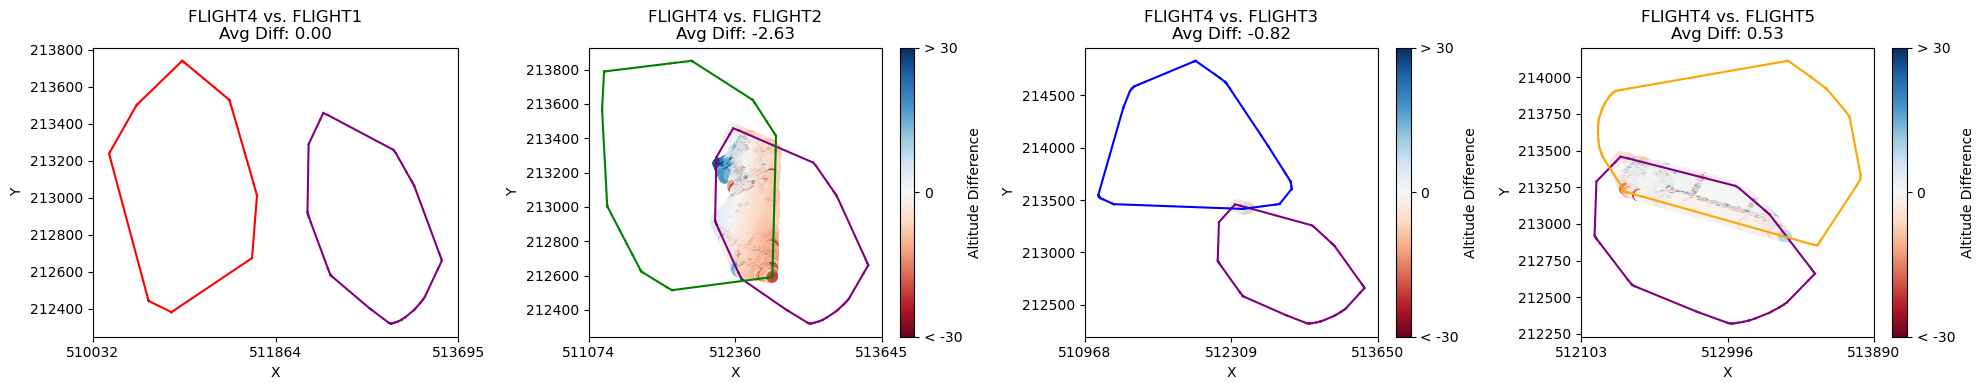

In [14]:
err.plot_patches_comparison(patches = vertices_list, ref_index=3, dist=1, colors=colors, labels=labels)

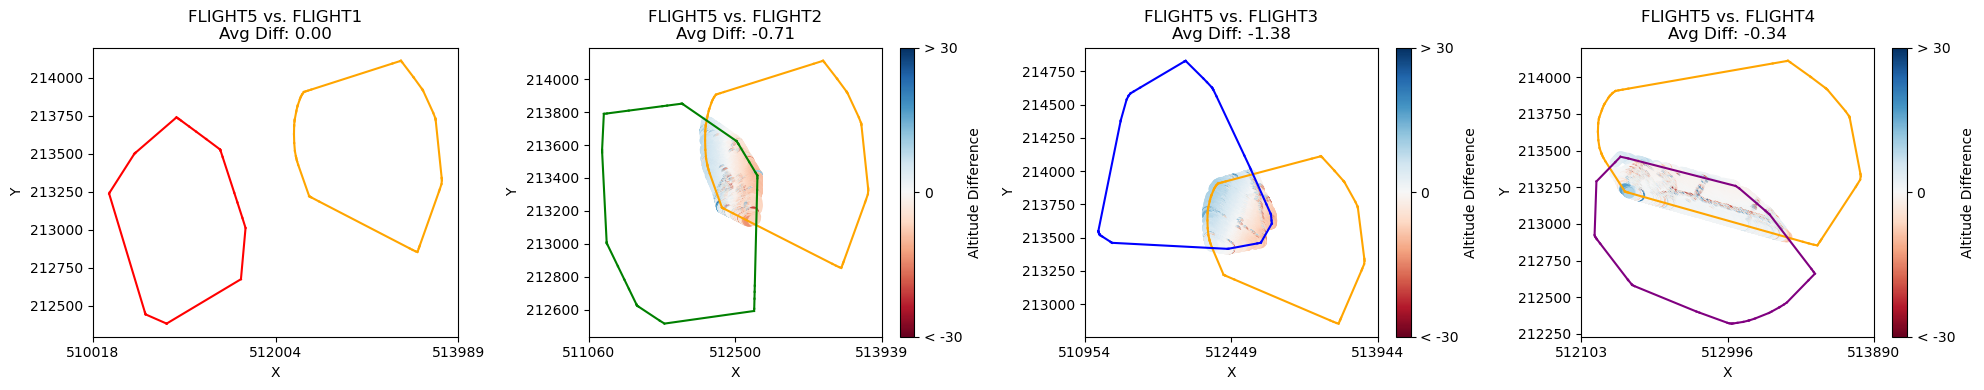

In [15]:
err.plot_patches_comparison(patches = vertices_list, ref_index=4, dist=1, colors=colors, labels=labels)

### Visualizing the maps in 3D

In [17]:
err.compare_map(vertices_4, vertices_2)

### Example 3D overlap between map 4 (red) and 2 (green)

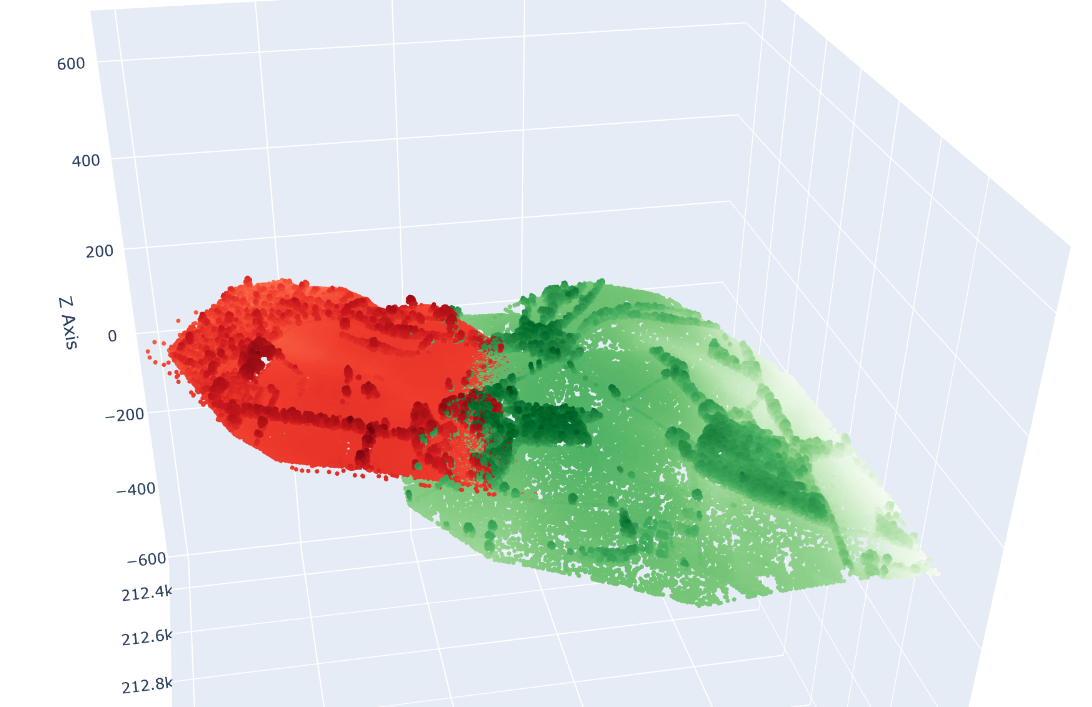

# Understanding the FIGSHARE MAPS
### FIGSHARE .OBJ are 10 time more dense, but are otherwise fully similar to BoB maps

In [15]:
vertices_1 = err.read_obj_vertices("ROTHAMSTED/FLIGHT1FIGSHARE/Flight_1.obj")
print(vertices_1.shape)

(4443127, 3)


In [16]:
vertices_2 = err.read_obj_vertices("ROTHAMSTED/FLIGHT2FIGSHARE/Flight_2.obj")
print(vertices_2.shape)

(5273351, 3)


In [17]:
vertices_3 = err.read_obj_vertices("ROTHAMSTED/FLIGHT3FIGSHARE/Flight_3.obj")
print(vertices_3.shape)

(4359460, 3)


In [18]:
vertices_4 = err.read_obj_vertices("ROTHAMSTED/FLIGHT4FIGSHARE/Flight_4.obj")
print(vertices_4.shape)

(8398542, 3)


In [19]:
vertices_5 = err.read_obj_vertices("ROTHAMSTED/FLIGHT5FIGSHARE/Flight_5.obj")
print(vertices_5.shape)

(3833930, 3)


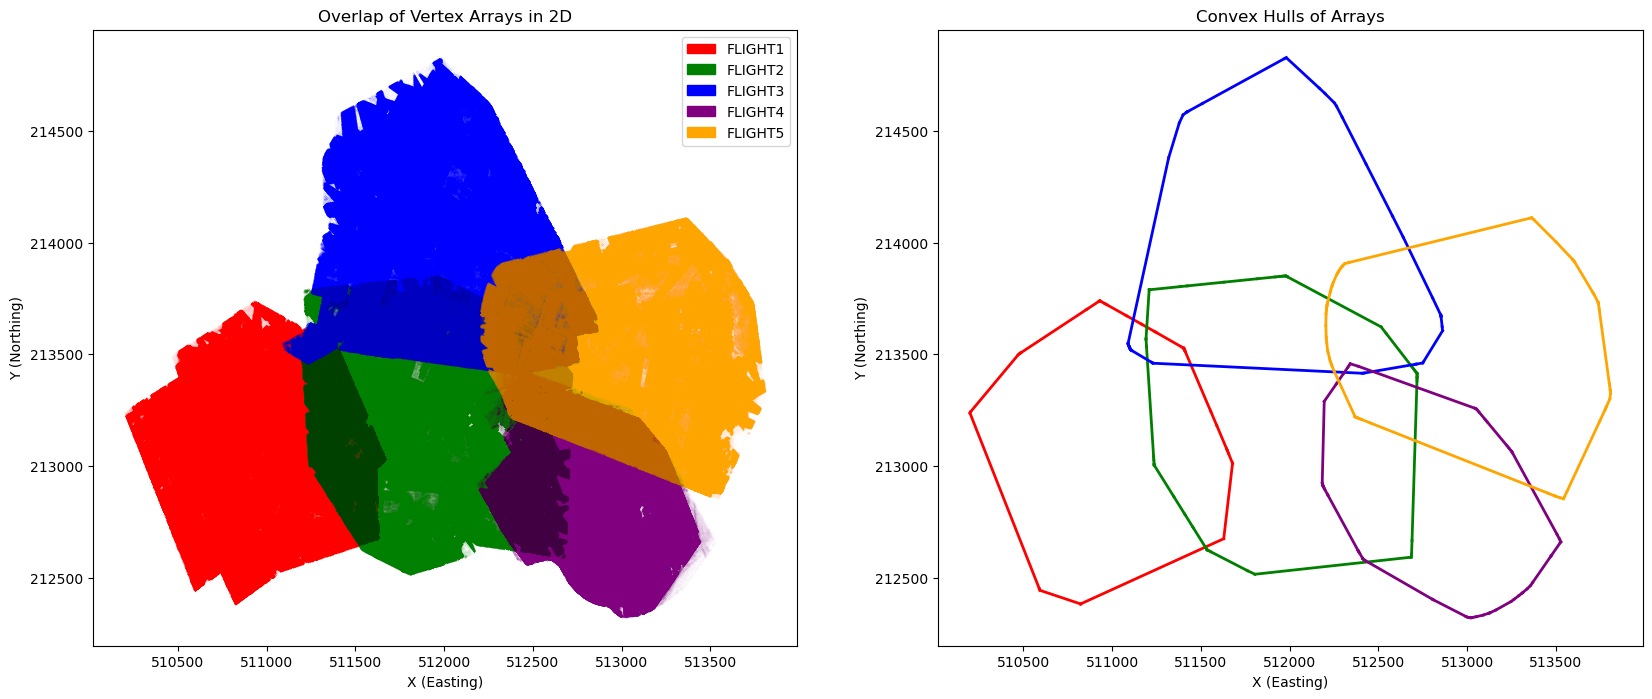

In [20]:
vertices_list = [vertices_1, vertices_2, vertices_3, vertices_4, vertices_5]
labels = labels=["FLIGHT1", "FLIGHT2", "FLIGHT3", "FLIGHT4", "FLIGHT5"]
colors = ['red', 'green', 'blue', 'purple', 'orange']
err.plot_vertex_overlaps_with_hulls(vertices_list, labels, colors)

# Stitch the five small dataset together, visualize

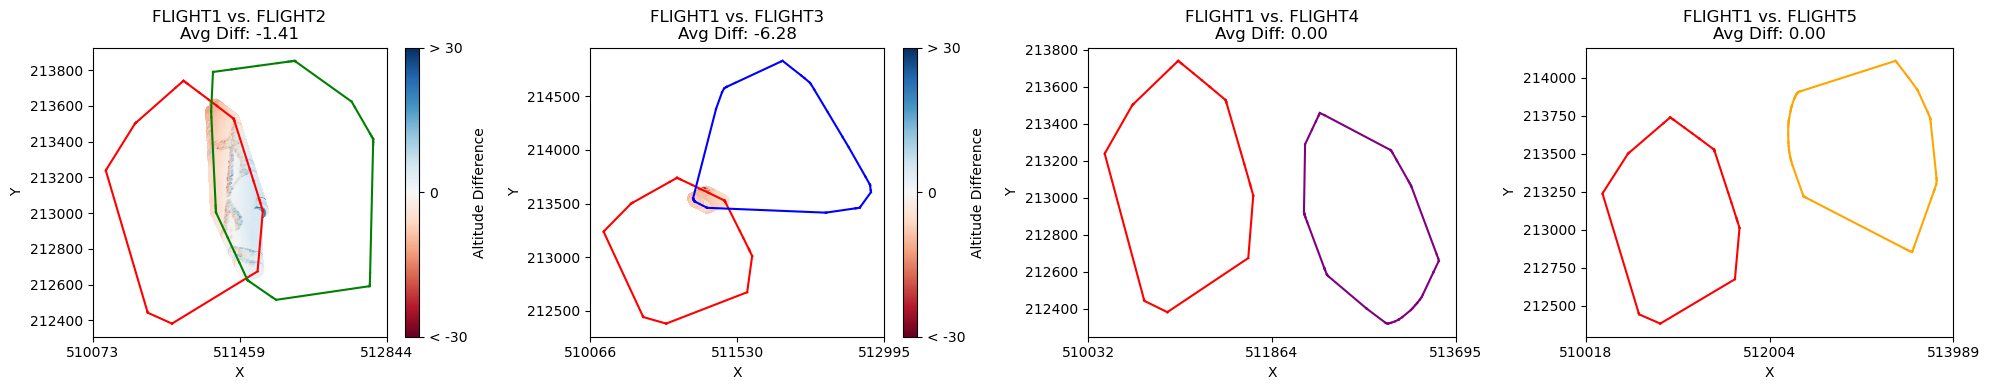

In [21]:
err.plot_patches_comparison(patches = vertices_list, ref_index=0, dist=1, colors=colors, labels=labels)

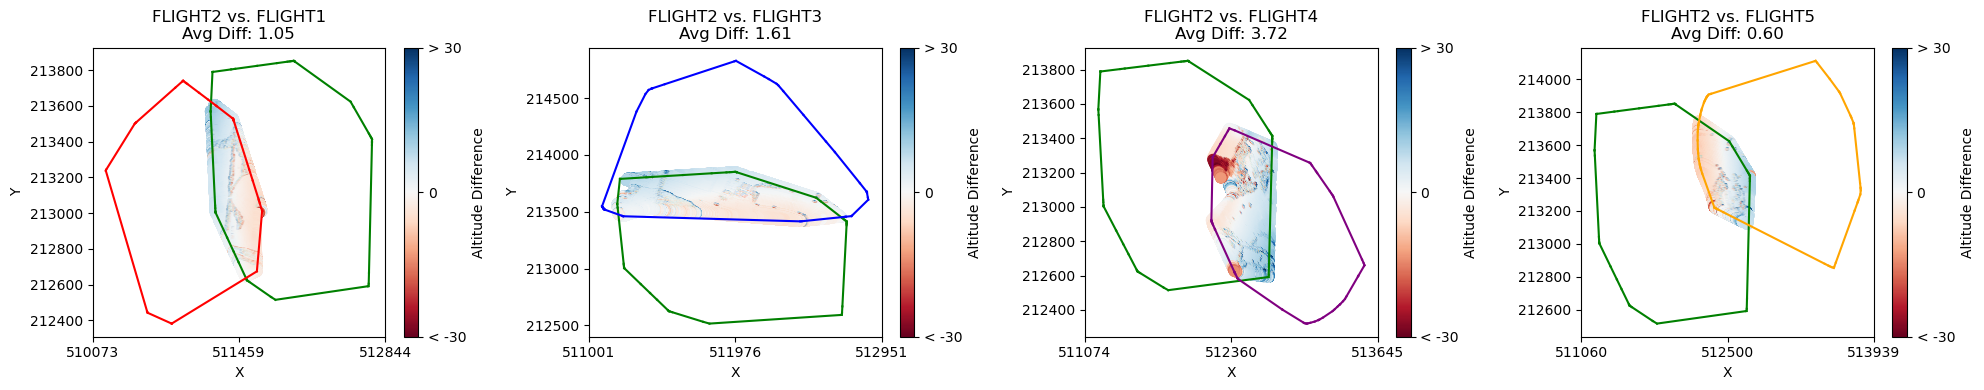

In [22]:
err.plot_patches_comparison(patches = vertices_list, ref_index=1, dist=1, colors=colors, labels=labels)

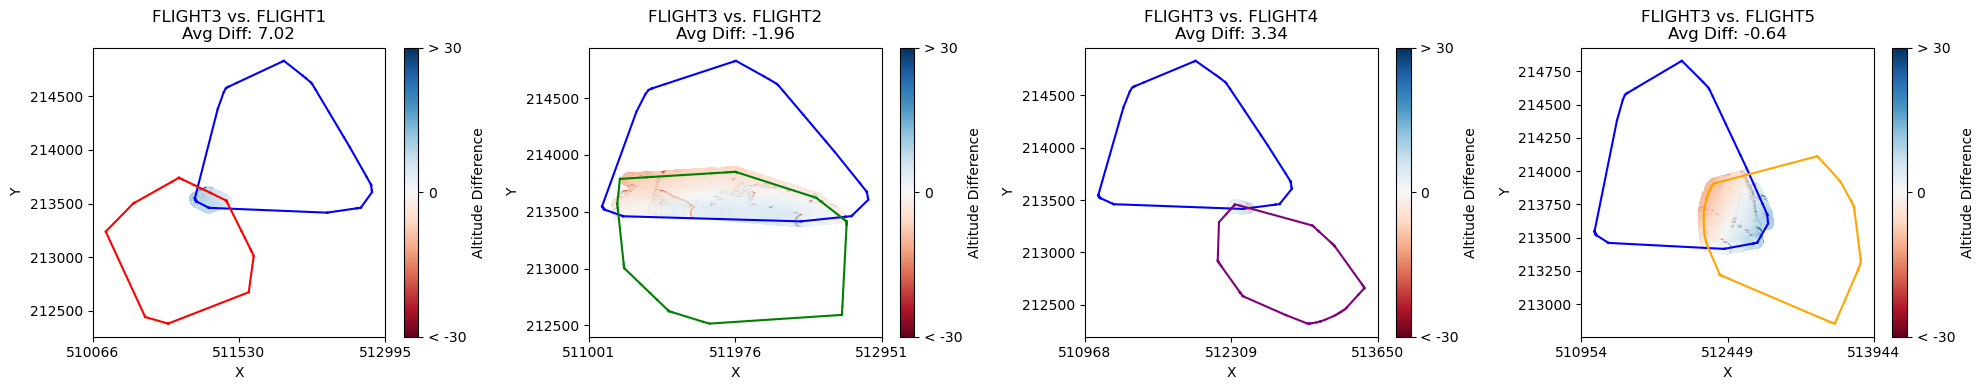

In [23]:
err.plot_patches_comparison(patches = vertices_list, ref_index=2, dist=1, colors=colors, labels=labels)

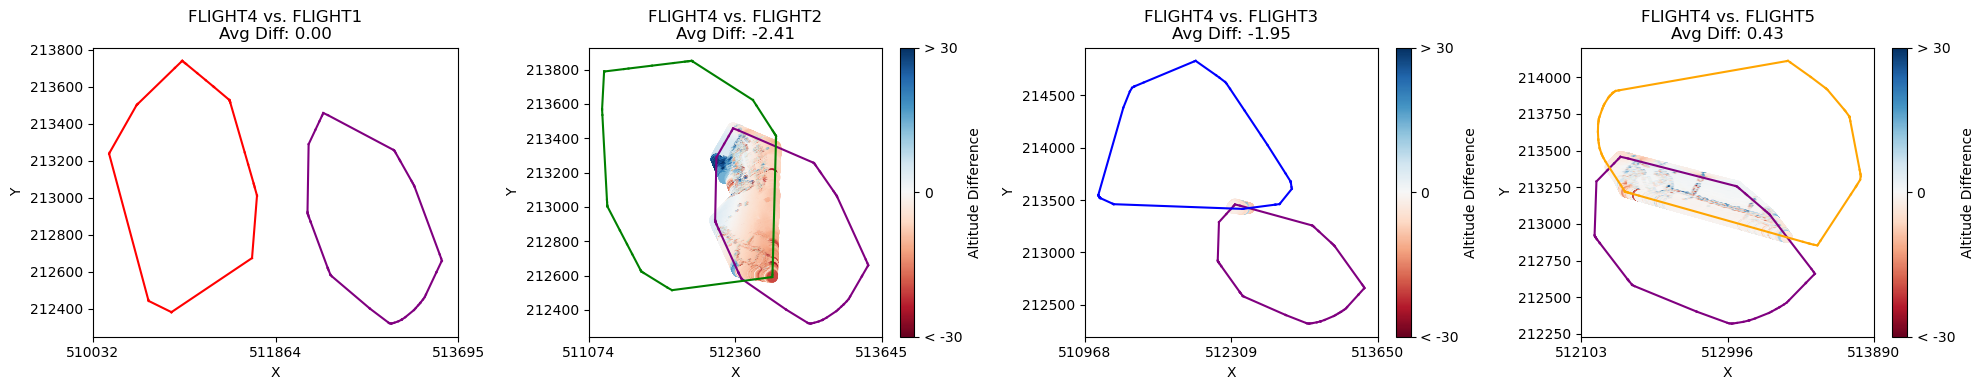

In [24]:
err.plot_patches_comparison(patches = vertices_list, ref_index=3, dist=1, colors=colors, labels=labels)

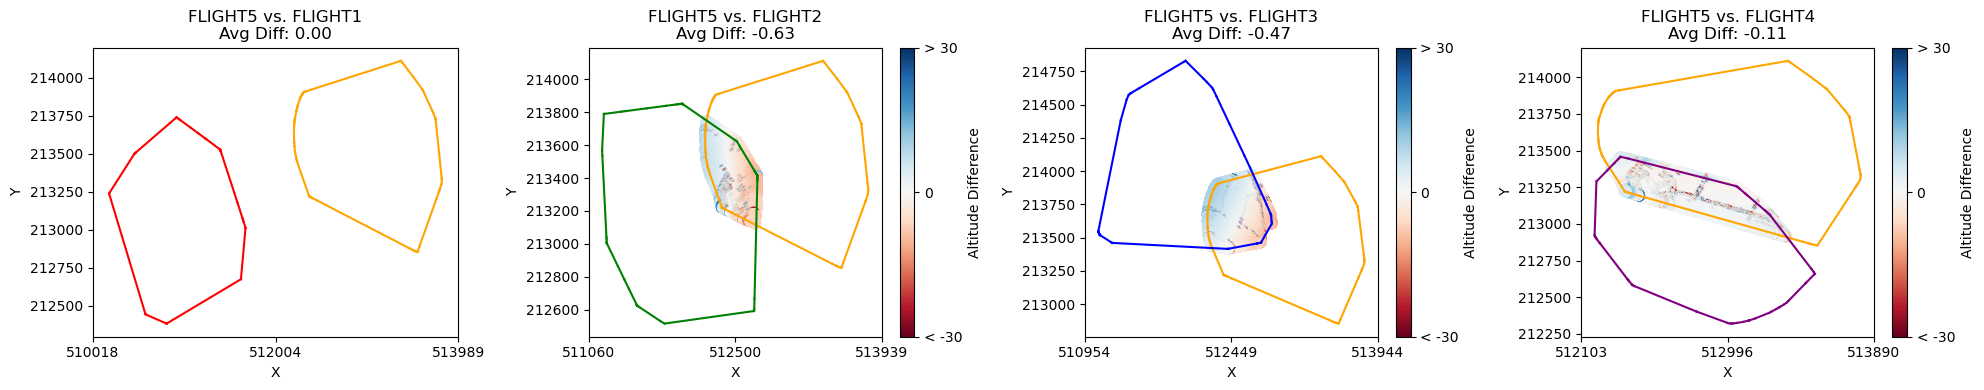

In [25]:
err.plot_patches_comparison(patches = vertices_list, ref_index=4, dist=1, colors=colors, labels=labels)

## Overview

- **Giant Map on FIGSHARE**: Spans all smaller models . 
    - **Issue**: Too large for direct use, crashes on load.
    - **Fix**: Requires downsampling.

- **Full Model Limitation**: Edges visible when high up.
    - **Needed**: More map coverage to prevent seeing the "end of the world."
orld."


In [3]:
vertices_full = err.read_obj_vertices("ROTHAMSTED/FULLFIGSHARE/3D_Model.obj")
print(vertices_full.shape)

(55221953, 3)


Area of convex hull: 10433.565598829138


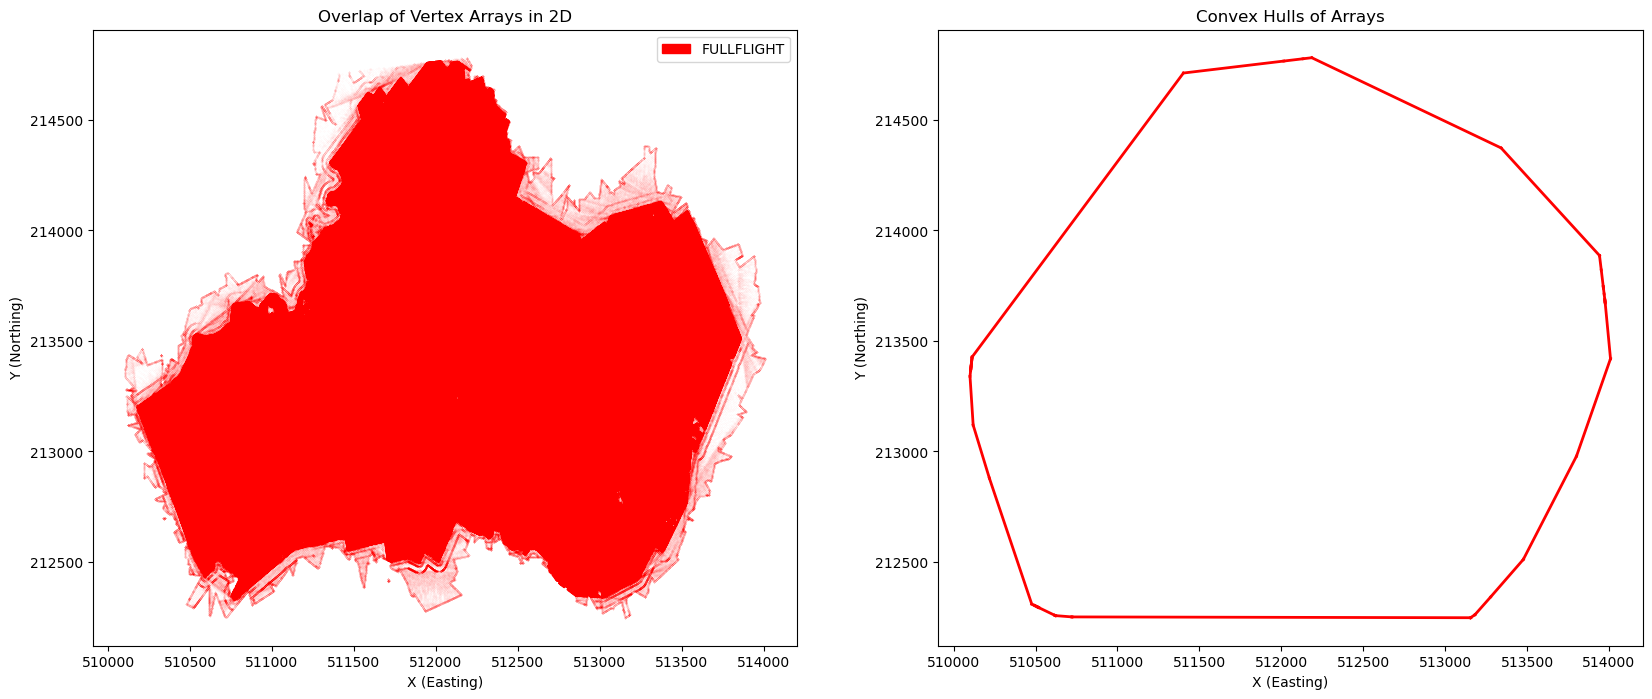

In [4]:
vertices_list = [vertices_full]
labels = labels=["FULLFLIGHT"]
colors = ['red']
err.plot_vertex_overlaps_with_hulls(vertices_list, labels, colors)